An autoencoder is a type of artificial neural network used to learn a compressed representation of input data and reconstruct the original data from it.

In simple words, an autoencoder learns to compress data and then reconstruct it as accurately as possible.

A. Encoder

The encoder takes the input data and converts it into a smaller or more compact representation.
For example, it may learn important features of a handwritten digit, such as its curves, edges, and shape.


B. Latent Space

The latent space is the compressed representation created by the encoder.
It retains useful information about the input while reducing the amount of information that needs to be represented.

C. Decoder

The decoder takes the compressed representation and reconstructs an output that resembles the original input.
For image denoising, the decoder tries to produce a clean image from the features learned from a noisy image.

Real-world applications

- Mobile photography: Reducing noise in photos taken in low light.

- CCTV surveillance: Improving the visual quality of grainy footage.
- Old photograph restoration: Reducing noise and some image degradation.
- Industrial inspection: Removing image noise to help examine manufactured components.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
# Load MNIST dataset
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


Normalize images

In [ ]:
# Convert pixel values from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Image shape:", x_train.shape)

Image shape: (60000, 28, 28, 1)


Add noise to images

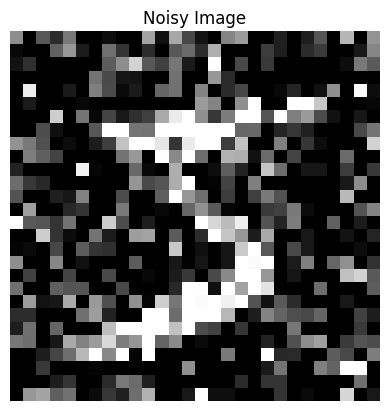

In [ ]:
# Add random noise
noise_factor = 0.4

x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_test.shape
)

# Keep pixel values between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy = np.clip(x_test_noisy, 0.0, 1.0)

# Display a noisy image
plt.imshow(x_train_noisy[0].squeeze(), cmap="gray")
plt.title("Noisy Image")
plt.axis("off")
plt.show()

Build the autoencoder model

In [ ]:
# Encoder
input_img = keras.Input(shape=(28, 28, 1))

x = layers.Conv2D(
    32, (3, 3), activation="relu", padding="same"
)(input_img)

x = layers.MaxPooling2D((2, 2), padding="same")(x)

x = layers.Conv2D(
    16, (3, 3), activation="relu", padding="same"
)(x)

encoded = layers.MaxPooling2D((2, 2), padding="same")(x)

# Decoder
x = layers.Conv2D(
    16, (3, 3), activation="relu", padding="same"
)(encoded)

x = layers.UpSampling2D((2, 2))(x)

x = layers.Conv2D(
    32, (3, 3), activation="relu", padding="same"
)(x)

x = layers.UpSampling2D((2, 2))(x)

decoded = layers.Conv2D(
    1, (3, 3), activation="sigmoid", padding="same"
)(x)

# Create autoencoder
autoencoder = keras.Model(input_img, decoded)

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

Train the autoencoder

In [ ]:
history = autoencoder.fit(
    x_train_noisy,
    x_train,
    epochs=10,
    batch_size=128,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 113s 237ms/step - loss: 0.1726 - val_loss: 0.1113
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 112s 238ms/step - loss: 0.1068 - val_loss: 0.1017
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 110s 236ms/step - loss: 0.1005 - val_loss: 0.0975
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 111s 236ms/step - loss: 0.0973 - val_loss: 0.0951
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 140s 232ms/step - loss: 0.0954 - val_loss: 0.0940
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 142s 231ms/step - loss: 0.0940 - val_loss: 0.0929
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 108s 231ms/step - loss: 0.0930 - val_loss: 0.0917
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 141s 229ms/step - loss: 0.0922 - val_loss: 0.0909
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 145s 236ms/step - loss: 0.0915 - val_loss: 0.0904
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 108s 230ms/step - loss: 0.0910 - val_loss: 0.0903


Generate denoised images

In [ ]:
# Predict clean images from noisy images
denoised_images = autoencoder.predict(x_test_noisy[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step


Display original, noisy, and denoised images

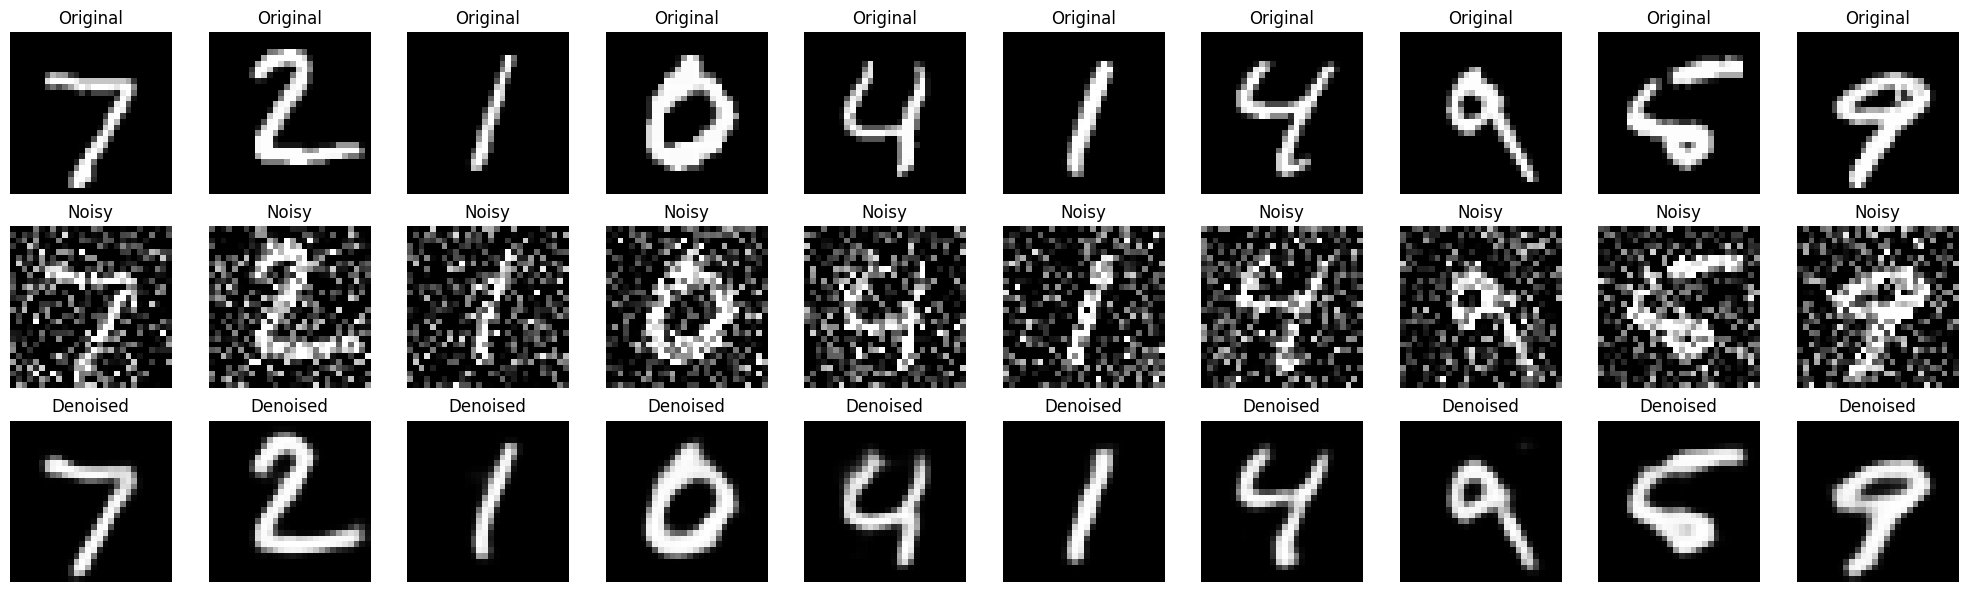

In [ ]:
n = 10

plt.figure(figsize=(20, 6))

for i in range(n):

    # Original image
    plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Noisy image
    plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].squeeze(), cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    # Denoised image
    plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(denoised_images[i].squeeze(), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()

Plot training and validation loss

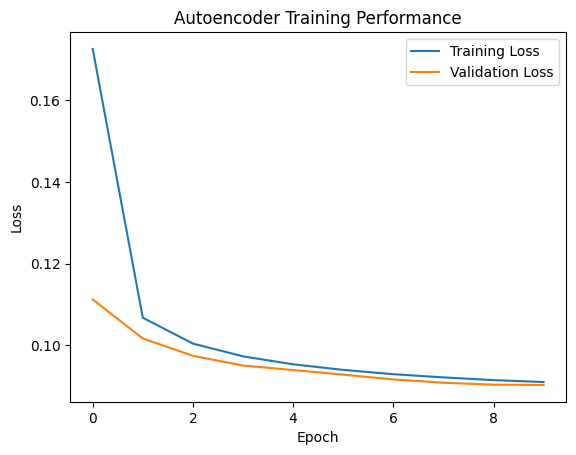

In [ ]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Autoencoder Training Performance")
plt.legend()
plt.show()